# Week 8 - WorkBook(Exercises) & Take Home

In [1]:
# Connect

import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")
milk.head(3)

,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
0,HS,2014,201401,January 2014,4,0,1,Imports,826,United Kingdom,...,None,None,None,None,22404316,None,21950747,None,None,0
1,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,60497363,None,46923551,None,None,0
2,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2520,None,3410,None,None,0


In [2]:
# Aggregate in SQL — GROUP BY
# Total trade value by trade flow and commodity, straight from the database:

summary = run_query("""
    SELECT [Trade Flow], [Commodity Code], SUM([Trade Value (US$)]) AS total_value
    FROM week09.comtrade_milk_uk_monthly_14
    GROUP BY [Trade Flow], [Commodity Code]
    ORDER BY total_value DESC
""")
summary

,Trade Flow,Commodity Code,total_value
0,Exports,0402,929722573
1,Exports,0401,867581317
2,Imports,0402,683554344
3,Imports,0401,444215541


In [4]:
# Monthly export totals:

monthly = run_query("""
    SELECT [Period], SUM([Trade Value (US$)]) AS exports
    FROM week09.comtrade_milk_uk_monthly_14
    WHERE [Trade Flow] = 'Exports'
    GROUP BY [Period]
    ORDER BY [Period]
""")

In [5]:
# Or aggregate in pandas 
# Pull the rows, then pivot — same result, pandas style:

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")
pivot = milk.pivot_table(
    index="Period",
    columns="Trade Flow",
    values="Trade Value (US$)",
    aggfunc="sum",
)

In [6]:
# Save to CSV
summary.to_csv("milk_trade_summary.csv", index=False)

In [7]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import matplotlib
matplotlib.rcParams['axes.grid'] = True # show gridlines by default
%matplotlib inline

import pandas as pd

In [9]:
if pd.__version__.startswith('0.23'):
    # this solves an incompatibility between pandas 0.23 and datareader 0.6
    # taken from https://stackoverflow.com/questions/50394873/
    core.common.is_list_like = api.types.is_list_like

from pandas_datareader.wb import download

In [12]:
YEAR = 2023
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdp = download(indicator=GDP_INDICATOR, country=['GB','CN'],
start=YEAR-5, end=YEAR)
gdp = gdp.reset_index()
gdp

,country,year,NY.GDP.MKTP.CD
0,China,2023,1.827036e+13
1,China,2022,1.831677e+13
2,China,2021,1.820170e+13
3,China,2020,1.499641e+13
4,China,2019,1.456017e+13
5,China,2018,1.414777e+13
6,United Kingdom,2023,3.420797e+12
7,United Kingdom,2022,3.181244e+12
8,United Kingdom,2021,3.194559e+12
9,United Kingdom,2020,2.724001e+12


In [ ]:
# Calculating the sum

gdp.groupby('country')['NY.GDP.MKTP.CD'].aggregate(sum)

country
China             9.849317e+13
United Kingdom    1.829334e+13
Name: NY.GDP.MKTP.CD, dtype: float64

In [14]:
# Calculating the Combined sum of both countries for each year

gdp.groupby('year')['NY.GDP.MKTP.CD'].aggregate(sum)

year
2018    1.704479e+13
2019    1.743588e+13
2020    1.772042e+13
2021    2.139626e+13
2022    2.149801e+13
2023    2.169115e+13
Name: NY.GDP.MKTP.CD, dtype: float64

In [ ]:
LOCATION='comtrade_milk_uk_monthly_14.csv'

In [19]:
LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=2014&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

In [9]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
# Commodity/Reporter codes are already stored as text (e.g. '0401'), so no dtype needed.
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")
milk.head(3)

,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
0,HS,2014,201401,January 2014,4,0,1,Imports,826,United Kingdom,...,None,None,None,None,22404316,None,21950747,None,None,0
1,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,60497363,None,46923551,None,None,0
2,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2520,None,3410,None,None,0


In [10]:
# Limit the columns to make the dataframe easier to work with by selecting just a subset of them.

COLUMNS = ['Year', 'Period','Trade Flow','Reporter', 'Partner', 'Commodity','Commodity Code','Trade Value (US$)']
milk = milk[COLUMNS]

In [22]:
# Derive two new dataframes that separate out the 'World' partner data and the data for individual partner countries.

milk_world = milk[milk['Partner'] == 'World']
milk_countries = milk[milk['Partner'] != 'World']

In [23]:
#store a local copy as a CSV file:

milk_countries.to_csv('countrymilk.csv', index=False)

In [24]:
# load the data back in:

load_test = run_query("SELECT * FROM week09.countrymilk")
load_test.head(2)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
0,2014,201401,Exports,United Kingdom,Afghanistan,"Milk and cream, neither concentrated nor sweet...",0401,3410
1,2014,201401,Exports,United Kingdom,Austria,"Milk and cream, neither concentrated nor sweet...",0401,316


In [25]:
# Subsetting Your Data

milk_imports = milk[milk['Trade Flow'] == 'Imports']
milk_countries_imports = milk_countries[milk_countries['Trade Flow'] == 'Imports']
milk_world_imports=milk_world[milk_world['Trade Flow'] == 'Imports']

In [26]:
# Sorting the data

milkImportsInJanuary2014 = milk_countries_imports[milk_countries_imports['Period'] == 201401]
milkImportsInJanuary2014.sort_values('Trade Value (US$)',ascending=False).head(10)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
23,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, neither concentrated nor sweet...",0401,10676138
626,2014,201401,Imports,United Kingdom,France,"Milk and cream, concentrated or sweetened",0402,8020014
637,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, concentrated or sweetened",0402,5966962
650,2014,201401,Imports,United Kingdom,Netherlands,"Milk and cream, concentrated or sweetened",0402,4650774
629,2014,201401,Imports,United Kingdom,Germany,"Milk and cream, concentrated or sweetened",0402,4545873
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
612,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, concentrated or sweetened",0402,3584038
10,2014,201401,Imports,United Kingdom,Denmark,"Milk and cream, neither concentrated nor sweet...",0401,2233438
667,2014,201401,Imports,United Kingdom,Spain,"Milk and cream, concentrated or sweetened",0402,1850097
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872


In [27]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import matplotlib
matplotlib.rcParams['axes.grid'] = True # show gridlines by default
%matplotlib inline

import pandas as pd

In [28]:
if pd.__version__.startswith('0.23'):
    # this solves an incompatibility between pandas 0.23 and datareader 0.6
    # taken from https://stackoverflow.com/questions/50394873/
    core.common.is_list_like = api.types.is_list_like

from pandas_datareader.wb import download

In [30]:
?download

Signature:
download(
    country=None,
    indicator=None,
    start=2003,
    end=2005,
    freq=None,
    errors='warn',
    **kwargs,
)
Docstring:
Download data series from the World Bank's World Development Indicators

Parameters
----------
indicator: string or list of strings
    taken from the ``id`` field in ``WDIsearch()``
country: string or list of strings.
    ``all`` downloads data for all countries
    2 or 3 character ISO country codes select individual
    countries (e.g.``US``,``CA``) or (e.g.``USA``,``CAN``).  The codes
    can be mixed.

    The two ISO lists of countries, provided by wikipedia, are hardcoded
    into pandas as of 11/10/2014.
start: int
    First year of the data series
end: int
    Last year of the data series (inclusive)
freq: str
    frequency or periodicity of the data to be retrieved (e.g. 'M' for
    monthly, 'Q' for quarterly, and 'A' for annual). None defaults to
    annual.
errors: str {'ignore', 'warn', 'raise'}, default 'warn'
    Country co

In [31]:
YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdp = download(indicator=GDP_INDICATOR, country=['GB','CN'],
start=YEAR-5, end=YEAR)
gdp = gdp.reset_index()
gdp

,country,year,NY.GDP.MKTP.CD
0,China,2013,9.743124e+12
1,China,2012,8.673665e+12
2,China,2011,7.671757e+12
3,China,2010,6.192565e+12
4,China,2009,5.189577e+12
5,China,2008,4.667346e+12
6,United Kingdom,2013,2.796908e+12
7,United Kingdom,2012,2.719716e+12
8,United Kingdom,2011,2.675590e+12
9,United Kingdom,2010,2.496741e+12


In [32]:
gdp.groupby('country')['NY.GDP.MKTP.CD'].aggregate(sum)

country
China             4.213803e+13
United Kingdom    1.606357e+13
Name: NY.GDP.MKTP.CD, dtype: float64

In [33]:
gdp.groupby('year')['NY.GDP.MKTP.CD'].aggregate(sum)

year
2008    7.612598e+12
2009    7.618935e+12
2010    8.689306e+12
2011    1.034735e+13
2012    1.139338e+13
2013    1.254003e+13
Name: NY.GDP.MKTP.CD, dtype: float64

In [34]:
LOCATION='comtrade_milk_uk_monthly_14.csv'

In [35]:
LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=2014&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

In [37]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
# Commodity/Reporter codes are already stored as text (e.g. '0401'), so no dtype needed.

import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")
milk.head(3)

,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
0,HS,2014,201401,January 2014,4,0,1,Imports,826,United Kingdom,...,None,None,None,None,22404316,None,21950747,None,None,0
1,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,60497363,None,46923551,None,None,0
2,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2520,None,3410,None,None,0


In [38]:
COLUMNS = ['Year', 'Period','Trade Flow','Reporter', 'Partner', 'Commodity','Commodity Code','Trade Value (US$)']
milk = milk[COLUMNS]

In [39]:
milk_world = milk[milk['Partner'] == 'World']
milk_countries = milk[milk['Partner'] != 'World']

In [40]:
milk_countries.to_csv('countrymilk.csv', index=False)

In [41]:
load_test = run_query("SELECT * FROM week09.countrymilk")
load_test.head(2)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
0,2014,201401,Exports,United Kingdom,Afghanistan,"Milk and cream, neither concentrated nor sweet...",0401,3410
1,2014,201401,Exports,United Kingdom,Austria,"Milk and cream, neither concentrated nor sweet...",0401,316


In [42]:
milk_imports = milk[milk['Trade Flow'] == 'Imports']
milk_countries_imports = milk_countries[milk_countries['Trade Flow'] == 'Imports']
milk_world_imports=milk_world[milk_world['Trade Flow'] == 'Imports']

In [43]:
milkImportsInJanuary2014 = milk_countries_imports[milk_countries_imports['Period'] == 201401]
milkImportsInJanuary2014.sort_values('Trade Value (US$)',ascending=False).head(10)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
23,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, neither concentrated nor sweet...",0401,10676138
626,2014,201401,Imports,United Kingdom,France,"Milk and cream, concentrated or sweetened",0402,8020014
637,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, concentrated or sweetened",0402,5966962
650,2014,201401,Imports,United Kingdom,Netherlands,"Milk and cream, concentrated or sweetened",0402,4650774
629,2014,201401,Imports,United Kingdom,Germany,"Milk and cream, concentrated or sweetened",0402,4545873
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
612,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, concentrated or sweetened",0402,3584038
10,2014,201401,Imports,United Kingdom,Denmark,"Milk and cream, neither concentrated nor sweet...",0401,2233438
667,2014,201401,Imports,United Kingdom,Spain,"Milk and cream, concentrated or sweetened",0402,1850097
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872


In [45]:
# Grouping the data
#Split the data into two different subsets of data (imports and exports), by grouping on trade flow.

groups = milk_countries.groupby('Trade Flow')

In [46]:
# Inspect the first few rows associated with a particular group:

groups.get_group('Imports').head()

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
10,2014,201401,Imports,United Kingdom,Denmark,"Milk and cream, neither concentrated nor sweet...",0401,2233438
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872
17,2014,201401,Imports,United Kingdom,Germany,"Milk and cream, neither concentrated nor sweet...",0401,1028700
23,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, neither concentrated nor sweet...",0401,10676138


In [47]:
groups.get_group('Exports').head()

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
2,2014,201401,Exports,United Kingdom,Afghanistan,"Milk and cream, neither concentrated nor sweet...",0401,3410
3,2014,201401,Exports,United Kingdom,Austria,"Milk and cream, neither concentrated nor sweet...",0401,316
5,2014,201401,Exports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,5663128
6,2014,201401,Exports,United Kingdom,Br. Virgin Isds,"Milk and cream, neither concentrated nor sweet...",0401,34566
7,2014,201401,Exports,United Kingdom,Canada,"Milk and cream, neither concentrated nor sweet...",0401,51017


In [48]:
GROUPING_COMMFLOW = ['Commodity Code','Trade Flow']

groups = milk_countries.groupby(GROUPING_COMMFLOW)
groups.groups.keys()

dict_keys([('0401', 'Exports'), ('0401', 'Imports'), ('0402', 'Exports'), ('0402', 'Imports')])

In [49]:
GROUPING_PARTNERFLOW = ['Partner','Trade Flow']
groups = milk_countries.groupby(GROUPING_PARTNERFLOW)

GROUP_PARTNERFLOW= ('France','Imports')
groups.get_group( GROUP_PARTNERFLOW )

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872
68,2014,201402,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1444455
120,2014,201403,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1414291
171,2014,201404,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1912257
223,2014,201405,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1638838
273,2014,201406,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1449614
327,2014,201407,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,2096771
370,2014,201408,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1474883
416,2014,201409,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1259777
466,2014,201410,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1483422


In [27]:
groups = milk_countries.groupby(['Commodity Code'])
groups.get_group('0402').sort_values("Trade Value (US$)", ascending=False).head()

NameError: name 'milk_countries' is not defined

# Week 8 Take Home

This week has two parts:

| Part | Lessons | Take-home work |
|------|---------|----------------|
| **A. Grouping & Aggregating Data** | `1-Grouping & Aggregating Data/` (notebooks 1–4) | Project 4 below + the notebook task solutions |
| **B. Data Visualization** | `2-Data Visualization (Seaborn & Matplotlib)/` (videos + scripts) | Re-create the plots from the videos using the Part A milk data: a histogram, a KDE plot, a box/violin plot, a regression plot and a heatmap. Add them at the end of this notebook. |

Part A data comes from the cohort database (schema `week09`). See `Data Access (SQL).md`.

---
# Part A: Grouping & Aggregating Data

## Project 4: Exploring the UK's milk imports and exports

A country's economy depends, sometimes heavily, on its exports and imports. The United Nations Comtrade database provides data on global trade. It will be used to analyse the UK's imports and exports of milk and cream in 2015:

- How much does the UK export and import and is the balance positive (more exports than imports)? 
- Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?
- Which are the regular customers, i.e. which countries buy milk from the UK every month?
- Which countries does the UK both import from and export to?

In [16]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

from pandas import *
%matplotlib inline

## Getting and preparing the data

The data is obtained from the [United Nations Comtrade](http://comtrade.un.org/data/) website, by selecting the following configuration:

- Type of Product: goods
- Frequency: monthly 
- Periods: January to May of 2015
- Reporter: United Kingdom
- Partners: all
- Flows: imports and exports
- HS (as reported) commodity codes: 0401 (Milk and cream, neither concentrated nor sweetened) and 0402 (Milk and cream, concentrated or sweetened)

Clicking on 'Preview' results in a message that the data exceeds 500 rows. Data was downloaded using the *Download CSV* button and the download file renamed appropriately.

In [5]:
LOCATION = 'comtrade_milk_uk_jan_jul_15.csv'

The data can also be downloaded directly from Comtrade using the "View API Call" URL, modified in two ways:

- `max=500` is increased to `max=5000` to make sure all data is loaded,
- `&fmt=csv` is added at the end to obtain the data in CSV format.

In [3]:
# LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=201505%2C201504%2C201503%2C201502%2C201501&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

On reading in the data, the commodity code has to be read as a string, to not lose the leading zero.

In [12]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_jan_jul_15")
milk.tail(2)


,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
635,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2213,None,37883,None,None,0
636,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,1588,None,5676,None,None,0


The data only covers the first five months of 2015. Most columns are irrelevant for this analysis, or contain always the same value, like the year and reporter columns. The commodity code is transformed into a short but descriptive text and only the relevant columns are selected.

In [15]:
def milkType(code):
    if code == '0401': # neither concentrated nor sweetened
        return 'unprocessed'
    if code == '0402': # concentrated or sweetened
        return 'processed' 
    return 'unknown'

COMMODITY = 'Milk and cream'
milk[COMMODITY] = milk['Commodity Code'].apply(milkType)
MONTH = 'Period'
PARTNER = 'Partner'
FLOW = 'Trade Flow'
VALUE = 'Trade Value (US$)'
headings = [MONTH, PARTNER, FLOW, COMMODITY, VALUE]
milk = milk[headings]
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
0,201501,World,Imports,unprocessed,14104602
1,201501,World,Exports,unprocessed,26259792
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271


The data contains the total imports and exports per month, under the 'World' partner. Those rows are removed to keep only the per-country data.

In [17]:
milk = milk[milk[PARTNER] != 'World']
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271
5,201501,Belgium,Exports,unprocessed,996031
6,201501,Bulgaria,Exports,unprocessed,191


## Total trade flow

To answer the first question, 'how much does the UK export and import and is the balance positive (more exports than imports)?',
the dataframe is split into two groups: exports from the UK and imports into the UK. The  trade values within each group are summed up to get the total trading.

In [18]:
grouped = milk.groupby([FLOW])
grouped[VALUE].aggregate(sum)

Trade Flow
Exports    265029661
Imports    156483978
Name: Trade Value (US$), dtype: int64

This shows a trade surplus of over 100 million dollars.

## Main trade partners

To address the second question, 'Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?', the dataframe is split by country instead, and then each group aggregated for the total trade value. This is done separately for imports and exports. The result is sorted in descending order so that the main partners are at the top.

In [19]:
imports = milk[milk[FLOW] == 'Imports']
grouped = imports.groupby([PARTNER])
print('The UK imports from', len(grouped), 'countries.')
print('The 5 biggest exporters to the UK are:')
totalImports = grouped[VALUE].aggregate(sum).sort_values(inplace=False,ascending=False)
totalImports.head()

The UK imports from 21 countries.
The 5 biggest exporters to the UK are:


/var/folders/jh/1fyqq_w57b9cg0xj874p_pxc0000gn/T/ipykernel_4558/110647639.py:5: Pandas4Warning: The inplace keyword in Series.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  totalImports = grouped[VALUE].aggregate(sum).sort_values(inplace=False,ascending=False)


Partner
Ireland        46263897
France         28314091
Germany        21899123
Netherlands    17658912
Belgium        14325697
Name: Trade Value (US$), dtype: int64

The export values can be plotted as a bar chart, making differences between countries easier to see.

<Axes: ylabel='Partner'>

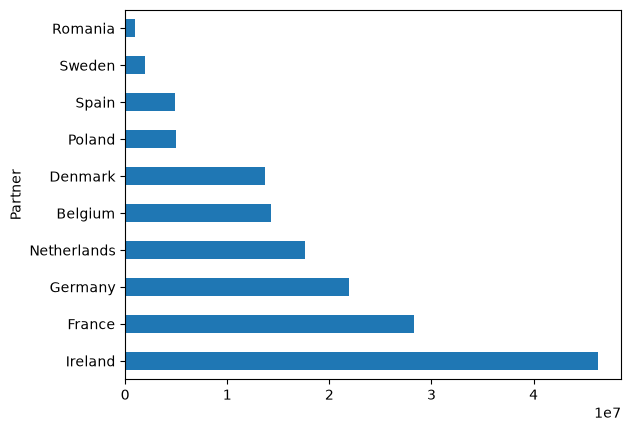

In [20]:
totalImports.head(10).plot(kind='barh')

In [21]:
exports = milk[milk[FLOW] == 'Exports']
grouped = exports.groupby([PARTNER])
print('The UK exports to', len(grouped), 'countries.')
print('The 5 biggest importers from the UK are:')
grouped[VALUE].aggregate(sum).sort_values(ascending=False,inplace=False).head()

The UK exports to 107 countries.
The 5 biggest importers from the UK are:


/var/folders/jh/1fyqq_w57b9cg0xj874p_pxc0000gn/T/ipykernel_4558/2707103549.py:5: Pandas4Warning: The inplace keyword in Series.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  grouped[VALUE].aggregate(sum).sort_values(ascending=False,inplace=False).head()


Partner
Ireland                 128155891
Netherlands              18018603
China                    14111163
Germany                  10828464
China, Hong Kong SAR      9482458
Name: Trade Value (US$), dtype: int64

## Regular importers

Given that there are two commodities, the third question, 'Which are the regular customers, i.e. which countries buy milk from the UK every month?', is meant in the sense that a regular customer imports both commodities every month. This means that if the exports dataframe is grouped by country, each group has exactly ten rows (two commodities bought each of the five months). To see the countries, only the first month of one commodity has to be listed, as by definition it's the same countries every month and for the other commodity.

In [22]:
def buysEveryMonth(group):
    return len(group) == 10

grouped = exports.groupby([PARTNER])
regular = grouped.filter(buysEveryMonth)
regular[(regular[MONTH] == 201501) & (regular[COMMODITY] == 'processed')]

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
268,201501,Belgium,Exports,processed,142610
271,201501,China,Exports,processed,1013141
275,201501,Cyprus,Exports,processed,6625
280,201501,Denmark,Exports,processed,107883
284,201501,France,Exports,processed,178262
287,201501,Germany,Exports,processed,2588380
292,201501,"China, Hong Kong SAR",Exports,processed,1110086
294,201501,Hungary,Exports,processed,2119
298,201501,Ireland,Exports,processed,4020981
300,201501,Italy,Exports,processed,23267


Just over 75% of the total UK exports are due to these regular customers.

In [23]:
regular[VALUE].sum() / exports[VALUE].sum()

np.float64(0.7583526396315317)

## Bi-directional trade

To address the fourth question, 
'Which countries does the UK both import from and export to?', a pivot table is used to list the total export and import value for each country. 

In [24]:
countries = pivot_table(milk, index=[PARTNER], columns=[FLOW], 
                        values=VALUE, aggfunc=sum)
countries.head()

Trade Flow,Exports,Imports
Partner,,
Algeria,8087885.0,NaN
Angola,2416129.0,NaN
Antigua and Barbuda,22218.0,NaN
"Areas, nes",51205.0,NaN
Australia,81644.0,NaN


Removing the rows with a missing value will result in only those countries with bi-directional trade flow with the UK.

In [25]:
countries.dropna()

Trade Flow,Exports,Imports
Partner,,
Austria,56279.0,780.0
Belgium,7209121.0,14325697.0
Czech Rep.,2590.0,486889.0
Denmark,335068.0,13681759.0
France,9381762.0,28314091.0
Germany,10828464.0,21899123.0
Hungary,71378.0,4762.0
Ireland,128155891.0,46263897.0
Italy,173689.0,321635.0


## Provide `1-Grouping & Aggregating Data/1.ipynb` Tasks Solutions below (Execute them)

In [ ]:
#Executed above

## Provide `1-Grouping & Aggregating Data/2.ipynb` Tasks Solutions below (Execute them)

In [ ]:
#Executed above

## Provide `1-Grouping & Aggregating Data/3.ipynb` Tasks Solutions below (Execute them)

In [35]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import matplotlib
matplotlib.rcParams['axes.grid'] = True # show gridlines by default
%matplotlib inline

import pandas as pd

In [36]:
data=[['A',10],['A',15],['A',5],['A',20],
['B',10],['B',10],['B',5],
['C',20],['C',30]]

df = pd.DataFrame(data=data, columns=["Commodity","Amount"])
df

,Commodity,Amount
0,A,10
1,A,15
2,A,5
3,A,20
4,B,10
5,B,10
6,B,5
7,C,20
8,C,30


In [40]:
grouped.get_group('B')

,Commodity,Amount
4,B,10
5,B,10
6,B,5


In [41]:
# First, add a Year column to the dataframe
df['Year'] = [2014, 2014, 2015, 2015, 2014, 2015, 2015, 2014, 2015]

# Now group by both Commodity and Year
grouped = df.groupby(['Commodity', 'Year'])

In [42]:
grouped.get_group( ('A',2014) )

,Commodity,Amount,Year
0,A,10,2014
1,A,15,2014


## Provide `1-Grouping & Aggregating Data/4.ipynb` Tasks Solutions below (Execute them)

In [43]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import matplotlib
matplotlib.rcParams['axes.grid'] = True # show gridlines by default
%matplotlib inline

import pandas as pd

In [44]:
if pd.__version__.startswith('0.23'):
    # this solves an incompatibility between pandas 0.23 and datareader 0.6
    # taken from https://stackoverflow.com/questions/50394873/
    core.common.is_list_like = api.types.is_list_like

from pandas_datareader.wb import download

In [46]:
LOCATION='comtrade_milk_uk_monthly_14.csv'

In [48]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
# Commodity/Reporter codes are already stored as text (e.g. '0401'), so no dtype needed.
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")
milk.head(3)

,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
0,HS,2014,201401,January 2014,4,0,1,Imports,826,United Kingdom,...,None,None,None,None,22404316,None,21950747,None,None,0
1,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,60497363,None,46923551,None,None,0
2,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2520,None,3410,None,None,0


In [49]:
COLUMNS = ['Year', 'Period','Trade Flow','Reporter', 'Partner', 'Commodity','Commodity Code','Trade Value (US$)']
milk = milk[COLUMNS]

In [51]:
milk_world = milk[milk['Partner'] == 'World']
milk_countries = milk[milk['Partner'] != 'World']


milk_countries.to_csv('countrymilk.csv', index=False)

In [52]:
load_test = run_query("SELECT * FROM week09.countrymilk")
load_test.head(2)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
0,2014,201401,Exports,United Kingdom,Afghanistan,"Milk and cream, neither concentrated nor sweet...",0401,3410
1,2014,201401,Exports,United Kingdom,Austria,"Milk and cream, neither concentrated nor sweet...",0401,316


In [54]:

milk_imports = milk[milk['Trade Flow'] == 'Imports']
milk_countries_imports = milk_countries[milk_countries['Trade Flow'] == 'Imports']
milk_world_imports=milk_world[milk_world['Trade Flow'] == 'Imports']

In [55]:
groups = milk_countries.groupby('Trade Flow')

In [56]:
groups.get_group('Imports').head()

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
10,2014,201401,Imports,United Kingdom,Denmark,"Milk and cream, neither concentrated nor sweet...",0401,2233438
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872
17,2014,201401,Imports,United Kingdom,Germany,"Milk and cream, neither concentrated nor sweet...",0401,1028700
23,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, neither concentrated nor sweet...",0401,10676138


In [57]:
GROUPING_COMMFLOW = ['Commodity Code','Trade Flow']

groups = milk_countries.groupby(GROUPING_COMMFLOW)
groups.groups.keys()

dict_keys([('0401', 'Exports'), ('0401', 'Imports'), ('0402', 'Exports'), ('0402', 'Imports')])

In [59]:

dict_keys([('0401', 'Exports'), ('0401', 'Imports'), ('0402', 'Exports'), ('0402', 'Imports')])

NameError: name 'dict_keys' is not defined

In [60]:
GROUPING_PARTNERFLOW = ['Partner','Trade Flow']
groups = milk_countries.groupby(GROUPING_PARTNERFLOW)

GROUP_PARTNERFLOW= ('France','Imports')
groups.get_group( GROUP_PARTNERFLOW )

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872
68,2014,201402,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1444455
120,2014,201403,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1414291
171,2014,201404,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1912257
223,2014,201405,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1638838
273,2014,201406,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1449614
327,2014,201407,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,2096771
370,2014,201408,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1474883
416,2014,201409,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1259777
466,2014,201410,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1483422


In [61]:
groups = milk_countries.groupby(['Commodity Code'])
groups.get_group('0402').sort_values("Trade Value (US$)", ascending=False).head()

KeyError: '0402'

In [62]:
data=[['A',10],['A',15],['A',5],['A',20],
['B',10],['B',10],['B',5],
['C',20],['C',30]]

df = pd.DataFrame(data=data, columns=["Commodity","Amount"])
df

,Commodity,Amount
0,A,10
1,A,15
2,A,5
3,A,20
4,B,10
5,B,10
6,B,5
7,C,20
8,C,30


In [63]:
grouped = df.groupby('Commodity')

In [64]:
grouped.groups.keys()

dict_keys(['A', 'B', 'C'])

In [66]:
grouped.get_group('B')

,Commodity,Amount
4,B,10
5,B,10
6,B,5


In [67]:
grouped = milk_countries.groupby(['Commodity','Year'])

In [68]:
grouped = milk_countries.groupby(['Commodity','Year'])
grouped.get_group( ('Milk and cream, neither concentrated nor sweetened',2014) )

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
2,2014,201401,Exports,United Kingdom,Afghanistan,"Milk and cream, neither concentrated nor sweet...",0401,3410
3,2014,201401,Exports,United Kingdom,Austria,"Milk and cream, neither concentrated nor sweet...",0401,316
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
5,2014,201401,Exports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,5663128
6,2014,201401,Exports,United Kingdom,Br. Virgin Isds,"Milk and cream, neither concentrated nor sweet...",0401,34566
...,...,...,...,...,...,...,...,...
600,2014,201412,Exports,United Kingdom,Sweden,"Milk and cream, neither concentrated nor sweet...",0401,9367
601,2014,201412,Imports,United Kingdom,United Arab Emirates,"Milk and cream, neither concentrated nor sweet...",0401,2572
602,2014,201412,Exports,United Kingdom,United Arab Emirates,"Milk and cream, neither concentrated nor sweet...",0401,33961
603,2014,201412,Exports,United Kingdom,Uganda,"Milk and cream, neither concentrated nor sweet...",0401,11545


In [69]:
grouped=df.groupby('Commodity')
grouped.aggregate(sum)

,Amount
Commodity,
A,50
B,25
C,50


In [70]:
def top2byAmount(g):
    return g.sort_values('Amount', ascending=False).head(2)
grouped.apply(top2byAmount)

Amount
Commodity          
A         3      20
          1      15
B         4      10
          5      10
C         8      30
          7      20

In [71]:
milk_world_imports.groupby('Commodity Code')['Trade Value (US$)'].aggregate(sum)

Commodity Code
0401    222107770
0402    341777173
Name: Trade Value (US$), dtype: int64

In [72]:
milk_imports_grouped=milk_countries_imports.groupby('Commodity Code')
milk_imports_grouped['Trade Value (US$)'].aggregate(sum)

Commodity Code
0401    222107771
0402    341777171
Name: Trade Value (US$), dtype: int64

In [73]:
milk_countries_imports_totals=milk_countries_imports.groupby('Partner')[['Trade Value (US$)']].aggregate(sum)
milk_countries_imports_totals.sort_values('Trade Value (US$)', ascending=False).head()

,Trade Value (US$)
Partner,
Ireland,174315886
France,105008176
Germany,76612700
Netherlands,72209235
Belgium,58338745


<Axes: ylabel='Commodity Code'>

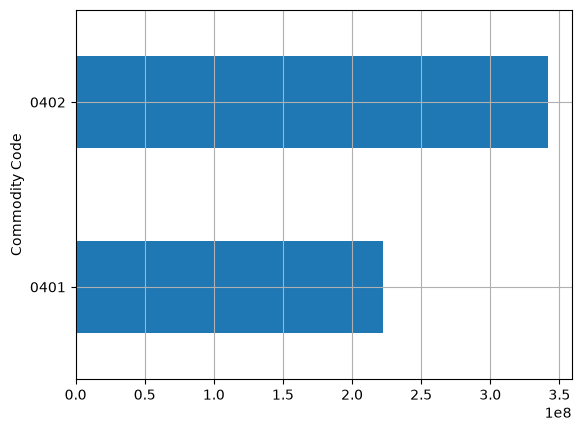

In [77]:
milk_imports_grouped['Trade Value (US$)'].aggregate(sum).plot(kind='barh')



In [78]:
monthlies=milk_countries_imports.groupby(['Commodity','Trade Flow','Period'])['Trade Value (US$)'].aggregate(sum)
monthlies

Commodity                                           Trade Flow  Period
Milk and cream, concentrated or sweetened           Imports     201401    30423330
                                                                201402    20614513
                                                                201403    26335257
                                                                201404    24770338
                                                                201405    26409462
                                                                201406    29081876
                                                                201407    25668642
                                                                201408    23360790
                                                                201409    37418160
                                                                201410    38012444
                                                                201411    39465351
                

In [79]:
from numpy import mean

GROUPING_COMMFLOWPERIOD=['Commodity','Trade Flow','Period']
milk_countries.groupby(GROUPING_COMMFLOWPERIOD)['Trade Value (US$)'].aggregate([sum, min, max, mean])

sum  \
Commodity                                          Trade Flow Period             
Milk and cream, concentrated or sweetened          Exports    201401  40215103   
                                                              201402  32298379   
                                                              201403  42987355   
                                                              201404  52900517   
                                                              201405  55987927   
                                                              201406  59594101   
                                                              201407  33370590   
                                                              201408  35080215   
                                                              201409  27320915   
                                                              201410  30387862   
                                                              201411  23417285   
                                                              201412  31301034   
                                                   Imports    201401  30423330   
                                                              201402  20614513   
                                                              201403  26335257   
                                                              201404  24770338   
                                                              201405  26409462   
                                                              201406  29081876   
                                                              201407  25668642   
                                                              201408  23360790   
                                                              201409  37418160   
                                                              201410  38012444   
                                                              201411  39465351   
                                                              201412  20217008   
Milk and cream, neither concentrated nor sweetened Exports    201401  46923551   
                                                              201402  40191337   
                                                              201403  43794069   
                                                              201404  42295261   
                                                              201405  40213208   
                                                              201406  39721799   
                                                              201407  39508126   
                                                              201408  26657488   
                                                              201409  33279378   
                                                              201410  26615555   
                                                              201411  25876673   
                                                              201412  28714207   
                                                   Imports    201401  21950746   
                                                              201402  18685554   
                                                              201403  17984197   
                                                              201404  19440269   
                                                              201405  21665662   
                                                              201406  16022428   
                                                              201407  19128109   
                                                              201408  16934043   
                                                              201409  19284385   
                                                              201410  18353099   
                                                              201411  17617864   
                                                         

<Axes: ylabel='Commodity Code,Period'>

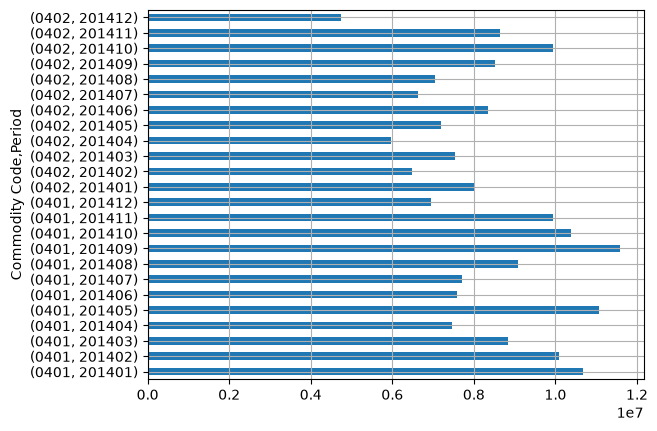

In [80]:
milk_countries_imports.groupby(['Commodity Code','Period'])['Trade Value (US$)'].aggregate(max).plot(kind='barh')

In [81]:
milk_bypartner_total=milk[milk["Trade Flow"]=='Imports'].groupby(['Partner'])['Trade Value (US$)'].aggregate(sum)
milk_bypartner_total.head(5)

Partner
Austria         798816
Belgium       58338745
Czech Rep.     1254989
Denmark       30534642
Finland             12
Name: Trade Value (US$), dtype: int64

/var/folders/jh/1fyqq_w57b9cg0xj874p_pxc0000gn/T/ipykernel_4558/3769720429.py:1: Pandas4Warning: The inplace keyword in Series.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  milk_bypartner_total.sort_values(ascending=False, inplace=False).head(5).plot(kind='barh')


<Axes: ylabel='Partner'>

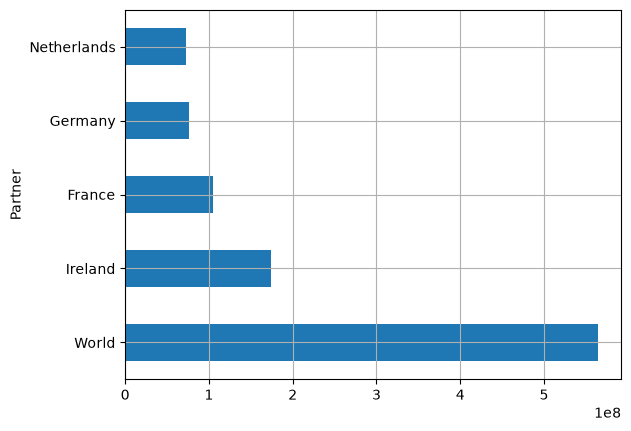

In [82]:
milk_bypartner_total.sort_values(ascending=False, inplace=False).head(5).plot(kind='barh')

## Conclusions

The milk and cream trade of the UK from January to May 2015 was analysed in terms of which countries the UK mostly depends on for income (exports) and goods (imports). Over the period, the UK had a trade surplus of over 100 million US dollars.

Ireland is the main partner, but it imported from the UK almost the triple in value than it exported to the UK. 

The UK exported to over 100 countries during the period, but only imported from 21 countries, the main ones (top five by trade value) being geographically close. China and Hong Kong are the main importers that are not also main exporters. 

The UK is heavily dependent on its regular customers, the 16 countries that buy all types of milk and cream every month. They contribute three quarters of the total export value.

The UK has bi-directional trade (i.e. both exports and imports) with 20 countries, although for some the trade value (in US dollars) is suspiciously low, which raises questions about the data's accuracy.


## Now repeat the analysis with your own data gotten from Comtrade website

## Tasks

In [103]:
# Task 1

#Loading the Singapore Trade Data

import pandas as pd

df = pd.read_csv("Singapore_TradeData_2023.csv")

display(df.head())

,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,False,0,False,3.122816e+10,NaN,3.122816e+10,0,False,True,NaN
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,True,0,False,2.228918e+04,NaN,2.228918e+04,4,False,True,NaN
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,True,0,False,1.319573e+05,NaN,1.319573e+05,4,False,True,NaN
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,True,0,False,1.164070e+08,NaN,1.164070e+08,4,False,True,NaN
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,True,0,False,5.634330e+02,NaN,5.634330e+02,4,False,True,NaN


In [ ]:
# Task 1.1
# Examining the dataset

# Display all column names
print(df.columns.tolist())

# Display the number of rows and columns
print(df.shape)

# Check the data types
df.info()

['typeCode', 'freqCode', 'refPeriodId', 'refYear', 'refMonth', 'period', 'reporterCode', 'reporterISO', 'reporterDesc', 'flowCode', 'flowDesc', 'partnerCode', 'partnerISO', 'partnerDesc', 'partner2Code', 'partner2ISO', 'partner2Desc', 'classificationCode', 'classificationSearchCode', 'isOriginalClassification', 'cmdCode', 'cmdDesc', 'aggrLevel', 'isLeaf', 'customsCode', 'customsDesc', 'mosCode', 'motCode', 'motDesc', 'qtyUnitCode', 'qtyUnitAbbr', 'qty', 'isQtyEstimated', 'altQtyUnitCode', 'altQtyUnitAbbr', 'altQty', 'isAltQtyEstimated', 'netWgt', 'isNetWgtEstimated', 'grossWgt', 'isGrossWgtEstimated', 'cifvalue', 'fobvalue', 'primaryValue', 'legacyEstimationFlag', 'isReported', 'isAggregate']
(4836, 47)
<class 'pandas.DataFrame'>
Index: 4836 entries, C to C
Data columns (total 47 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   typeCode                  4836 non-null   str    
 1   freqCode                  483

In [ ]:
# Task 1.2
# Removing World Partner

trade = df[df["partnerDesc"] != "World"].copy()

display(trade.head())

,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,False,0,False,3.122816e+10,NaN,3.122816e+10,0,False,True,NaN
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,True,0,False,2.228918e+04,NaN,2.228918e+04,4,False,True,NaN
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,True,0,False,1.319573e+05,NaN,1.319573e+05,4,False,True,NaN
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,True,0,False,1.164070e+08,NaN,1.164070e+08,4,False,True,NaN
C,M,20230101,2023,1,202301,702,SGP,Singapore,M,Import,...,True,0,False,5.634330e+02,NaN,5.634330e+02,4,False,True,NaN


In [ ]:
# Task 1.3
# Identifying Singapore's biggest trading partners

# Group by trade flow and partner country

import pandas as pd

# Load dataset
df = pd.read_csv(
    "Singapore_TradeData_2023.csv",
    index_col=False
)

# Remove World aggregate
trade = df[df["partnerDesc"] != "World"].copy()

# Calculate trade value by partner and trade flow
partners = trade.groupby(
    ["flowDesc", "partnerDesc"]
)["primaryValue"].sum().reset_index()

# Top 10 import partners
top_imports = partners[
    partners["flowDesc"] == "Import"
].sort_values(
    by="primaryValue",
    ascending=False
).head(10)

# Top 10 export partners
top_exports = partners[
    partners["flowDesc"] == "Export"
].sort_values(
    by="primaryValue",
    ascending=False
).head(10)

print("Singapore's Top 10 Import Partners")
display(top_imports)

print("Singapore's Top 10 Export Partners")
display(top_exports)

Singapore's Top 10 Import Partners


,flowDesc,partnerDesc,primaryValue
264,Import,China,5.876460e+10
428,Import,USA,5.204403e+10
374,Import,"Other Asia, nes",4.858574e+10
345,Import,Malaysia,4.760924e+10
328,Import,Japan,2.120023e+10
321,Import,Indonesia,1.599073e+10
298,Import,France,1.379716e+10
431,Import,United Arab Emirates,1.222163e+10
417,Import,Thailand,1.201321e+10
303,Import,Germany,1.006082e+10


Singapore's Top 10 Export Partners


,flowDesc,partnerDesc,primaryValue
43,Export,China,6.554982e+10
44,Export,"China, Hong Kong SAR",5.036983e+10
205,Export,USA,4.494046e+10
122,Export,Malaysia,4.445128e+10
98,Export,Indonesia,3.536610e+10
151,Export,"Other Asia, nes",2.054954e+10
105,Export,Japan,1.934309e+10
194,Export,Thailand,1.909418e+10
216,Export,Viet Nam,1.666266e+10
12,Export,Australia,1.513113e+10


In [ ]:
# Task 2.1

# Group data by commodity, trade partner and trade flow
commodity_trade = trade.groupby(
    ["cmdDesc", "flowDesc", "partnerDesc"]
)["primaryValue"].sum().reset_index()

# Sort from highest to lowest trade value
commodity_trade = commodity_trade.sort_values(
    by="primaryValue",
    ascending=False
)

# Find the largest partner for each commodity and trade flow
top_commodity_partners = commodity_trade.groupby(
    ["cmdDesc", "flowDesc"]
).head(1)

# Display results
display(top_commodity_partners)

,cmdDesc,flowDesc,partnerDesc,primaryValue
43,All Commodities,Export,China,6.554982e+10
264,All Commodities,Import,China,5.876460e+10


In [13]:
# Task 2.2

# Group by year, trade flow, commodity and partner
grouped_trade = trade.groupby(
    ["refYear", "flowDesc", "cmdDesc", "partnerDesc"]
)["primaryValue"].sum().reset_index()

# Sort by total trade value, highest first
grouped_trade = grouped_trade.sort_values(
    by="primaryValue",
    ascending=False
)

# Find the largest partner in each group
top_partners = grouped_trade.groupby(
    ["refYear", "flowDesc", "cmdDesc"]
).head(1)

# Display the results
display(top_partners)



,refYear,flowDesc,cmdDesc,partnerDesc,primaryValue
43,2023,Export,All Commodities,China,6.554982e+10
264,2023,Import,All Commodities,China,5.876460e+10


In [15]:
# Task 2.3: top 10 trading partners by imports and exports



# Group by trading partner and trade flow
partner_totals = trade.groupby(
    ["flowDesc", "partnerDesc"]
)["primaryValue"].sum().reset_index()

# Convert values into billions of US dollars
partner_totals["trade_usd_billions"] = (
    partner_totals["primaryValue"] / 1_000_000_000
).round(2)

# Top 10 import partners
top_10_imports = partner_totals[
    partner_totals["flowDesc"] == "Import"
].sort_values(
    by="primaryValue",
    ascending=False
).head(10)

# Top 10 export partners
top_10_exports = partner_totals[
    partner_totals["flowDesc"] == "Export"
].sort_values(
    by="primaryValue",
    ascending=False
).head(10)

print("Top 10 Import Partners")
display(top_10_imports)

print("Top 10 Export Partners")
display(top_10_exports)

Top 10 Import Partners


,flowDesc,partnerDesc,primaryValue,trade_usd_billions
264,Import,China,5.876460e+10,58.76
428,Import,USA,5.204403e+10,52.04
374,Import,"Other Asia, nes",4.858574e+10,48.59
345,Import,Malaysia,4.760924e+10,47.61
328,Import,Japan,2.120023e+10,21.20
321,Import,Indonesia,1.599073e+10,15.99
298,Import,France,1.379716e+10,13.80
431,Import,United Arab Emirates,1.222163e+10,12.22
417,Import,Thailand,1.201321e+10,12.01
303,Import,Germany,1.006082e+10,10.06


Top 10 Export Partners


,flowDesc,partnerDesc,primaryValue,trade_usd_billions
43,Export,China,6.554982e+10,65.55
44,Export,"China, Hong Kong SAR",5.036983e+10,50.37
205,Export,USA,4.494046e+10,44.94
122,Export,Malaysia,4.445128e+10,44.45
98,Export,Indonesia,3.536610e+10,35.37
151,Export,"Other Asia, nes",2.054954e+10,20.55
105,Export,Japan,1.934309e+10,19.34
194,Export,Thailand,1.909418e+10,19.09
216,Export,Viet Nam,1.666266e+10,16.66
12,Export,Australia,1.513113e+10,15.13


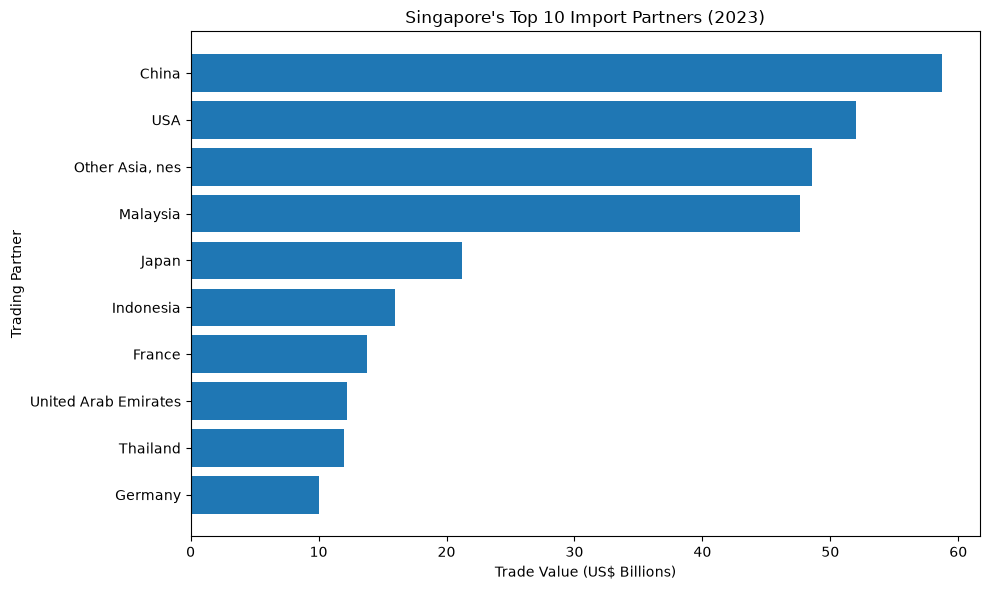

In [ ]:
# Taks 2.4 
# Create bar charts of Singapore's biggest Import partners

import matplotlib.pyplot as plt

# Top 10 import partners
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_imports["partnerDesc"],
    top_10_imports["trade_usd_billions"]
)

plt.xlabel("Trade Value (US$ Billions)")
plt.ylabel("Trading Partner")
plt.title("Singapore's Top 10 Import Partners (2023)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

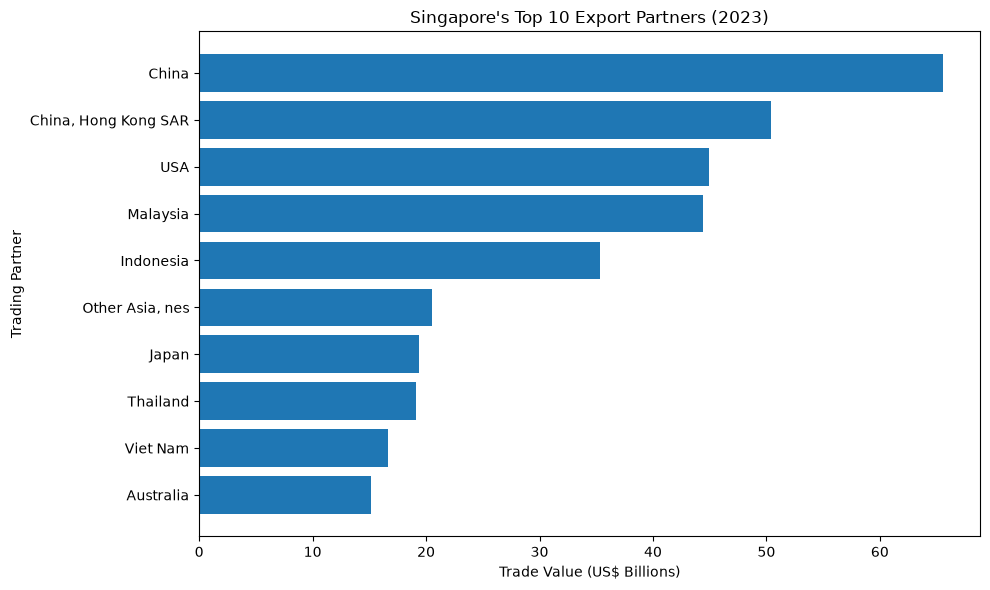

In [17]:
# Taks 2.5
# Create bar charts of Singapore's biggest Export partners

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_exports["partnerDesc"],
    top_10_exports["trade_usd_billions"]
)

plt.xlabel("Trade Value (US$ Billions)")
plt.ylabel("Trading Partner")
plt.title("Singapore's Top 10 Export Partners (2023)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Task 3

#### 1. How did I group the data, and what questions did I ask?

I used Python's Pandas library, particularly the groupby() function, to analyse Singapore's international trade data for 2023. I grouped the dataset by trade flow (imports and exports), trading partner, commodity, and year. I then used sum() to calculate the total value of trade for each group and sort_values() to identify the largest trading partners.

The main questions I wanted to answer were: Which countries are Singapore's largest import and export partners? Are the countries Singapore imports from also its biggest export destinations? How much trade does Singapore conduct with each country?

Since my dataset contains only the All Commodities category, I focused on overall trade relationships rather than individual products.


#### 2. Which countries were Singapore's major trading partners?

Major Import Partners : China, United states, Other Asia, Malaysia & Japan

Major Export Partners : China, Hong Kong, United states, Malaysia & Indonesia


China was Singapore's largest trading partner for both imports and exports in the dataset. The United States and Malaysia also featured prominently in both categories, suggesting significant two-way trade relationships.

Hong Kong was particularly important as an export destination, while Japan was among Singapore's largest import partners. Because the dataset covers only 2023 and combines all commodities, grouping by year and commodity did not produce additional meaningful categories.


Highest trade month:
202303 78.38

Lowest trade month:
202302 66.56


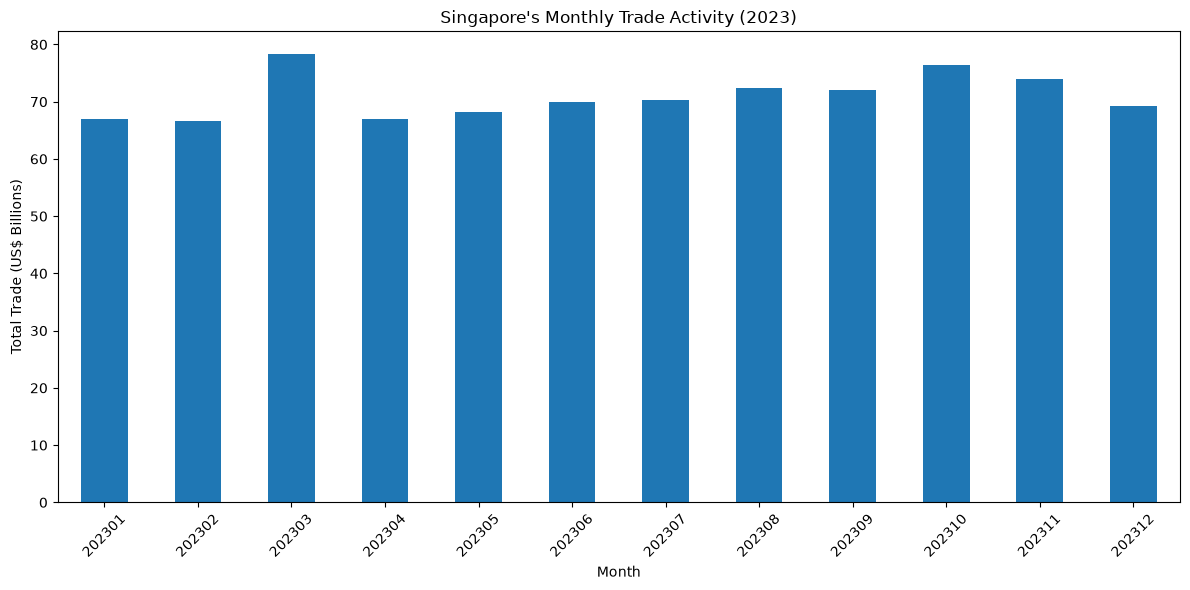

In [ ]:
# Task 4.1 : Which months had the highest and lowest trade activity?

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "Singapore_TradeData_2023.csv",
    index_col=False
)

# Use World totals to avoid double counting
world = df[df["partnerDesc"] == "World"].copy()

# Total imports and exports each month
monthly = world.groupby("period")["primaryValue"].sum()

# Convert to billions of US dollars
monthly = monthly / 1_000_000_000

print("Highest trade month:")
print(monthly.idxmax(), round(monthly.max(), 2))

print("\nLowest trade month:")
print(monthly.idxmin(), round(monthly.min(), 2))

# Plot monthly trade
monthly.plot(
    kind="bar",
    figsize=(12, 6),
    title="Singapore's Monthly Trade Activity (2023)"
)

plt.xlabel("Month")
plt.ylabel("Total Trade (US$ Billions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



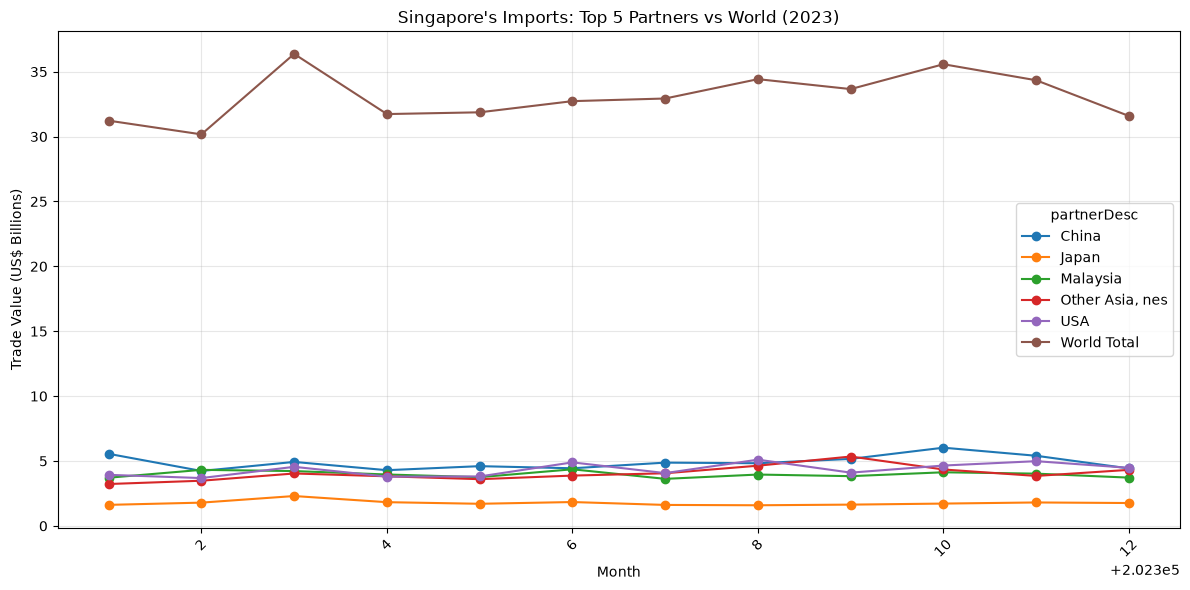

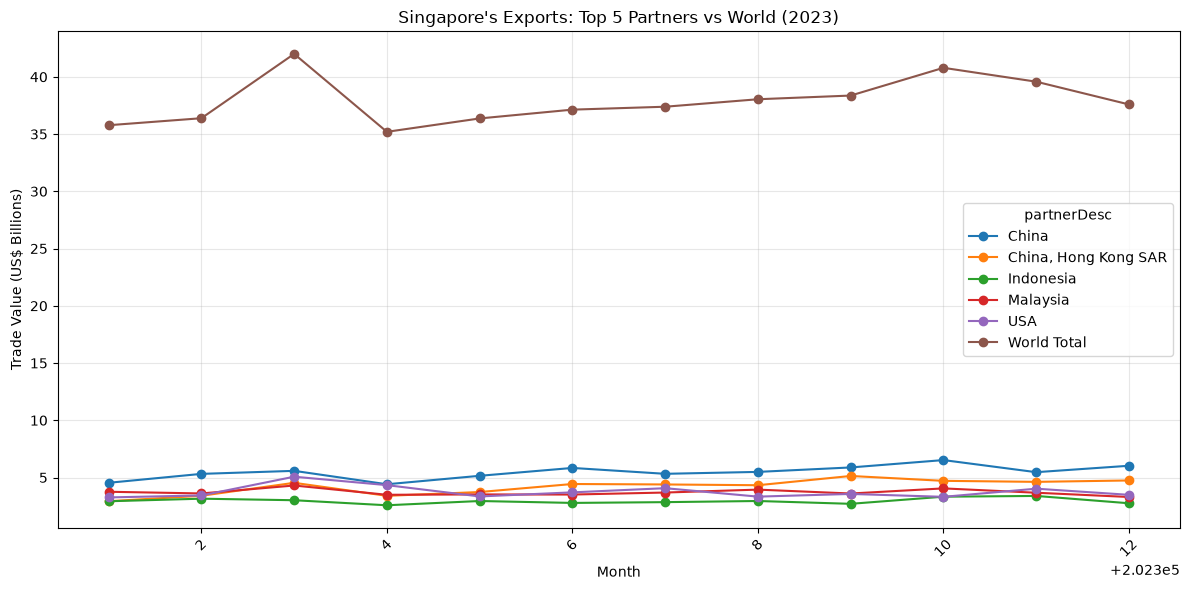

In [19]:
# Task 4.2 : Compare leading trading partners against World totals

# Exclude World from individual partner rankings
trade = df[df["partnerDesc"] != "World"].copy()

for flow in ["Import", "Export"]:

    flow_data = trade[trade["flowDesc"] == flow]

    # Identify top 5 partners by annual trade value
    top_5 = (
        flow_data.groupby("partnerDesc")["primaryValue"]
        .sum()
        .nlargest(5)
        .index
    )

    # Monthly values for the top partners
    partner_monthly = flow_data[
        flow_data["partnerDesc"].isin(top_5)
    ].pivot_table(
        index="period",
        columns="partnerDesc",
        values="primaryValue",
        aggfunc="sum",
        fill_value=0
    )

    # World total for this trade flow
    world_monthly = world[
        world["flowDesc"] == flow
    ].set_index("period")["primaryValue"]

    # Combine for comparison
    comparison = partner_monthly.copy()
    comparison["World Total"] = world_monthly

    # Convert to US$ billions
    comparison = comparison / 1_000_000_000

    comparison.plot(
        kind="line",
        marker="o",
        figsize=(12, 6),
        title=f"Singapore's {flow}s: Top 5 Partners vs World (2023)"
    )

    plt.xlabel("Month")
    plt.ylabel("Trade Value (US$ Billions)")
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

##### Task 4.3:  Did any trading partners dominate Singapore's trade?

China was Singapore's largest individual trading partner for both imports and exports, accounting for approximately 14.8% of imports and 14.4% of exports.

However, when comparing individual partner flows with the World totals, no single country completely dominated Singapore's trade. Even China's share was below 15% annually in both directions. This suggests that Singapore maintains a relatively diversified network of international trading partners, although several major partners collectively account for a substantial portion of its trade.



---
# Part B: Data Visualization

Add your seaborn/matplotlib plots below. Use the milk trade data from Part A. Give each plot a title and labelled axes, and write one sentence under it saying what it shows.

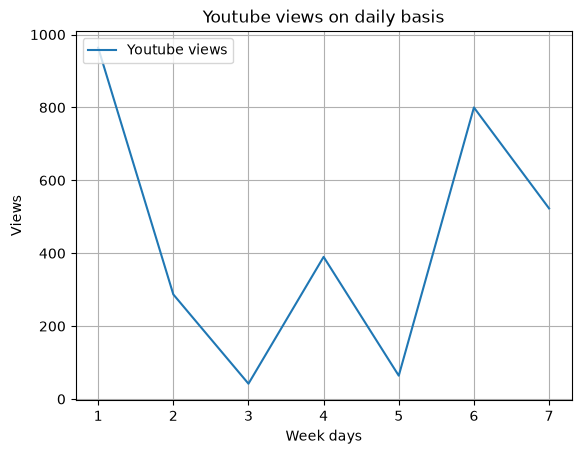

In [ ]:
## Matplotlib

import matplotlib.pyplot as plt

x=[1,2,3,4,5,6,7] # week days
y=[964,287,42,390,64,800,523] # views

plt.plot(x,y,label='Youtube views')
plt.xlabel('Week days')
plt.ylabel('Views')
plt.title('Youtube views on daily basis')
plt.legend(loc='upper left')
plt.show()

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you split, applied and combined the UK milk-trade data with `groupby` and `pivot_table`, then plotted it. Now answer the same kind of questions **in SQL**, straight from the `week09` tables: `GROUP BY` is SQL's split-apply-combine.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [93]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   4,
   4
  ],
  "58c6ed3aa1049eff4acfe5edcb59b1d51d4a45f3579bb7c1db90ae2724f0e865"
 ],
 "s02": [
  [
   12,
   4
  ],
  "cf8e205c894ca889a22c89cfce94e601860d25931f62e999f4408800c74d8280"
 ],
 "s03": [
  [
   10,
   3
  ],
  "d6dcb9773bc969b74418a8b0a4bcc92581bf839100b25d7b16d2710934ca53d8"
 ],
 "s04": [
  [
   6,
   5
  ],
  "d940a4dfa48898fdeea545a6f4a693d039a8601cb0ad38d9f20bab0e641840d1"
 ],
 "s05": [
  [
   30,
   4
  ],
  "92f2c46acfb66aa693f51c79b678dbfed4d60714ebfb6c6a3a5d08e585879061"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Split-apply-combine: GROUP BY two columns",
 "s02": "A monthly imports vs exports table",
 "s03": "Subtotals with GROUPING SETS",
 "s04": "Top 3 partners per trade flow (window function)",
 "s05": "A tidy table for a stacked bar chart"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Split-apply-combine: GROUP BY two columns

Use the 2015 data, `week09.comtrade_milk_uk_jan_jul_15` (it covers January–May 2015). Group it by **trade flow** and
**milk type**, like the lesson's `milk.groupby([FLOW, COMMODITY])`. The milk type comes from the commodity code:
`'0401'` → `'unprocessed'`, `'0402'` → `'processed'`.

**Return:** `trade_flow`, `milk_type`, `partners` (how many **different** partner countries), `total_musd` (total
trade value in **millions** of US$, **rounded to 2 dp**). Sort by `trade_flow`, then `milk_type` (both A→Z).
⚠️ Remove the `Partner = 'World'` rows first: they are monthly totals, so keeping them counts everything twice.
💡 `CASE [Commodity Code] WHEN '0401' THEN ... END`, `COUNT(DISTINCT Partner)`, and `GROUP BY` the same `CASE`
expression.

In [94]:
SQL_01 = """
SELECT
    [Trade Flow] AS trade_flow,

    CASE
        WHEN [Commodity Code] = '0401' THEN 'unprocessed'
        WHEN [Commodity Code] = '0402' THEN 'processed'
    END AS milk_type,

    COUNT(DISTINCT Partner) AS partners,

    ROUND(SUM([Trade Value (US$)]) / 1000000.0, 2) AS total_musd

FROM week09.comtrade_milk_uk_jan_jul_15

WHERE Partner <> 'World'

GROUP BY
    [Trade Flow],
    CASE
        WHEN [Commodity Code] = '0401' THEN 'unprocessed'
        WHEN [Commodity Code] = '0402' THEN 'processed'
    END

ORDER BY trade_flow ASC, milk_type ASC
"""
p.sql("s01", SQL_01)

,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


✅ s01: correct!


,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


### SQL Task 2 · A monthly imports vs exports table

`week09.countrymilk` is the clean 2014 data: one row per month, flow, partner and commodity, with the
`'World'` rows already removed. Build the table that `pivot_table(index='Period', columns='Trade Flow', ...)` gives you,
but in SQL: **one row per month**, imports and exports side by side, plus the trade balance.

**Return:** `period` (e.g. `201401`), `imports_musd`, `exports_musd`, `balance_musd` (exports − imports), all in
**millions of US$, rounded to 2 dp**. Sort by `period`.
⚠️ Work out the balance from the **unrounded** sums and round only at the end (rounding first can be 0.01 off).
💡 Conditional aggregation: `SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END)`. `PIVOT`
works too. Look at the result: is the balance positive in every month?

In [96]:
SQL_02 = """
WITH monthly_trade AS (
    SELECT
        Period AS period,

        SUM(CASE
            WHEN [Trade Flow] = 'Imports'
            THEN [Trade Value (US$)]
            ELSE 0
        END) AS total_imports,

        SUM(CASE
            WHEN [Trade Flow] = 'Exports'
            THEN [Trade Value (US$)]
            ELSE 0
        END) AS total_exports

    FROM week09.countrymilk

    GROUP BY Period
)

SELECT
    period,

    ROUND(total_imports / 1000000.0, 2) AS imports_musd,

    ROUND(total_exports / 1000000.0, 2) AS exports_musd,

    ROUND(
        (total_exports - total_imports) / 1000000.0,
        2
    ) AS balance_musd

FROM monthly_trade

ORDER BY period
"""
p.sql("s02", SQL_02)

,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


✅ s02: correct!


,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


### SQL Task 3 · Subtotals with GROUPING SETS

A manager wants a **quarterly report for 2014** (`week09.countrymilk`) with a **year subtotal** under each trade
flow, in one query.

**Return:** `trade_flow`, `quarter` (`'Q1'` … `'Q4'`, or `'Year'` on the subtotal row), `total_musd` (millions of
US$, **rounded to 2 dp**). That is 10 rows: for each flow, Q1–Q4 and then its `'Year'` row. Sort by `trade_flow`
(A→Z), then the quarters in order, with the `'Year'` row last.
💡 Quarter from `Period`: `(Period % 100 + 2) / 3` gives 1–4 (integer division). Then
`GROUP BY GROUPING SETS ((flow, quarter), (flow))`, and `GROUPING(quarter) = 1` tells you a row is a subtotal.
⚠️ Don't add a grand total over both flows: adding imports to exports is not a meaningful number.

In [99]:

SQL_03 = """
WITH trade_data AS (
    SELECT
        [Trade Flow] AS trade_flow,
        (Period % 100 + 2) / 3 AS quarter,
        [Trade Value (US$)] AS trade_value
    FROM week09.countrymilk
    WHERE Period BETWEEN 201401 AND 201412
)

SELECT
    trade_flow,

    CASE
        WHEN GROUPING(quarter) = 1 THEN 'Year'
        ELSE 'Q' + CAST(quarter AS VARCHAR(1))
    END AS quarter,

    ROUND(SUM(trade_value) / 1000000.0, 2) AS total_musd

FROM trade_data

GROUP BY GROUPING SETS (
    (trade_flow, quarter),
    (trade_flow)
)

ORDER BY
    trade_flow ASC,
    GROUPING(quarter) ASC,
    quarter ASC
"""

p.sql("s03", SQL_03)

,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


✅ s03: correct!


,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


### SQL Task 4 · Top 3 partners per trade flow (window function)

Project 4 asks: *which are the main trading partners?* Answer it for **both flows at once** using 2014
(`week09.countrymilk`): the **top 3 partners by total trade value in each trade flow**, and each partner's share of
that flow's total.

**Return:** `trade_flow`, `rank` (1–3), `partner`, `total_musd` (millions of US$, **rounded to 2 dp**), `share_pct`
(the partner's % of **its flow's** total over all partners, **rounded to 1 dp**). Sort by `trade_flow`, then `rank`.
💡 First total per (flow, partner) in a CTE. Then `ROW_NUMBER() OVER (PARTITION BY flow ORDER BY total DESC,
partner)` and `SUM(total) OVER (PARTITION BY flow)` for the share. Filter `rank <= 3` in the outer query (you can't
filter on a window function in the same `WHERE`).

In [100]:
SQL_04 = """
WITH partner_totals AS (
    SELECT
        [Trade Flow] AS trade_flow,
        Partner AS partner,
        SUM([Trade Value (US$)]) AS total_usd
    FROM week09.countrymilk
    GROUP BY [Trade Flow], Partner
),
ranked_partners AS (
    SELECT
        trade_flow,
        partner,
        total_usd,

        ROW_NUMBER() OVER (
            PARTITION BY trade_flow
            ORDER BY total_usd DESC, partner ASC
        ) AS [rank],

        SUM(total_usd) OVER (
            PARTITION BY trade_flow
        ) AS flow_total

    FROM partner_totals
)

SELECT
    trade_flow,
    [rank],
    partner,
    ROUND(total_usd / 1000000.0, 2) AS total_musd,
    ROUND(100.0 * total_usd / NULLIF(flow_total, 0), 1) AS share_pct

FROM ranked_partners

WHERE [rank] <= 3

ORDER BY trade_flow ASC, [rank] ASC
"""

p.sql("s04", SQL_04)

,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


✅ s04: correct!


,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


### SQL Task 5 · A tidy table for a stacked bar chart

For **Part B** you want a stacked bar chart of the UK's **2015 exports** (`week09.comtrade_milk_uk_jan_jul_15`):
one bar per month, split into the **5 biggest export partners** plus one `'Other'` slice for everyone else. Seaborn
likes **tidy (long)** data: one row per month and partner group. Build that table in SQL.

The "top 5" are the 5 partners with the largest **total** exports over all five months (ties: partner A→Z). Every
other partner becomes `'Other'`.

**Return:** `period`, `partner_group`, `exports_musd` (millions of US$, **rounded to 2 dp**), `share_pct` (the group's
% of **that month's** exports, **rounded to 1 dp**). 30 rows. Sort by `period`, then `partner_group` A→Z but with
`'Other'` last in each month.
⚠️ Exports only, and no `'World'` rows.
💡 CTE 1: the export rows. CTE 2: `SELECT TOP 5 Partner ... GROUP BY Partner ORDER BY SUM(...) DESC, Partner`.
`LEFT JOIN` the rows to the top 5 and use `CASE` to label the rest `'Other'`. For the share:
`SUM(SUM(v)) OVER (PARTITION BY period)` (a window over a grouped result).

In [101]:
SQL_05 = """
WITH exports AS (
    SELECT
        Period AS period,
        Partner AS partner,
        [Trade Value (US$)] AS trade_value
    FROM week09.comtrade_milk_uk_jan_jul_15
    WHERE [Trade Flow] = 'Exports'
      AND Partner <> 'World'
),

top_5 AS (
    SELECT TOP 5
        partner
    FROM exports
    GROUP BY partner
    ORDER BY SUM(trade_value) DESC, partner ASC
),

grouped_exports AS (
    SELECT
        e.period,
        CASE
            WHEN t.partner IS NOT NULL THEN e.partner
            ELSE 'Other'
        END AS partner_group,
        e.trade_value
    FROM exports AS e
    LEFT JOIN top_5 AS t
        ON e.partner = t.partner
)

SELECT
    period,
    partner_group,

    ROUND(
        SUM(trade_value) / 1000000.0, 2
    ) AS exports_musd,

    ROUND(
        100.0 * SUM(trade_value) /
        NULLIF(
            SUM(SUM(trade_value)) OVER (
                PARTITION BY period
            ), 0
        ), 1
    ) AS share_pct

FROM grouped_exports

GROUP BY period, partner_group

ORDER BY
    period ASC,
    CASE WHEN partner_group = 'Other' THEN 1 ELSE 0 END,
    partner_group ASC
"""

p.sql("s05", SQL_05)

,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


✅ s05: correct!


,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


### Practice score
Run this when you're done.

In [102]:
p.score()

Task Type                                           Topic Result
 s01  SQL       Split-apply-combine: GROUP BY two columns      ✅
 s02  SQL              A monthly imports vs exports table      ✅
 s03  SQL                    Subtotals with GROUPING SETS      ✅
 s04  SQL Top 3 partners per trade flow (window function)      ✅
 s05  SQL            A tidy table for a stacked bar chart      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Split-apply-combine: GROUP BY two columns,✅
1,s02,SQL,A monthly imports vs exports table,✅
2,s03,SQL,Subtotals with GROUPING SETS,✅
3,s04,SQL,Top 3 partners per trade flow (window function),✅
4,s05,SQL,A tidy table for a stacked bar chart,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).